# BARC-SS example: HUC8 11110203, trapezoidal channel a = 0.4

OWP HAND-FIM rating curves miss the river channel below the water surface because the DEM does not capture it. This notebook adds that channel to the hydrotables with `barc_ss.py`, then runs HAND-FIM with [FIMserv](https://github.com/sdmlua/FIMserv):

- **BARC**: adds the bankfull channel area and wetted perimeter to the hydrotable and recomputes discharge with Manning's equation.
- **BARC-SS**: BARC, plus shifts each rating curve's stage up by the reach's mean-flow depth and anchors it at zero flow.

Example: **HUC8 11110203** (Arkansas River), **trapezoidal channel with a = 0.4**, flood of **3 January 2016, 00:00**.

FIMserv writes `code/`, `data/`, and `output/` folders next to this notebook.

### STEP 1. Install and import

Install once:
```bash
pip install fimserve "git+https://github.com/Reizrb/HydroGeom"
```

In [1]:
import sys
sys.path.append("..")          # barc_ss.py is in the repository's main folder

import fimserve as fm
import matplotlib.pyplot as plt
import barc_ss

### STEP 2. Settings

- `method`: `"BARC"` or `"BARC-SS"`
- `shape` and `value`: channel shape used to compute bankfull area and wetted perimeter
  - `"a"`: trapezoid, `value` = bottom width / top width (0 = triangle, 1 = rectangle)
  - `"r"`: Dingman's r, `value` = r (1 = triangle, 2 = parabola, larger = rectangle)
  - `"z"`: side slope, `value` = z (z:1)

In [2]:
huc = "11110203"
method = "BARC-SS"
shape, value = "a", 0.4

start_date = "2015-12-26"
end_date = "2016-01-05"
value_times = ["2016-01-03 00:00:00"]

flood_dir = f"output/flood_{huc}"

### STEP 3. Download OWP HAND-FIM (version 4.5) with FIMserv

In [3]:
fm.DownloadHUC8(huc, version="4.5")

Repository already exists at /Users/reihanehzarrabi/Bathymetric-Adjustment-of-Rating-Curves-and-Stage-Shift-BARC-SS/examples/code/inundation-mapping. Skipping clone.


download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000043/hydroTable_2284000043.csv to output/flood_11110203/11110203/branches/2284000043/hydroTable_2284000043.csv


download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000025/hydroTable_2284000025.csv to output/flood_11110203/11110203/branches/2284000025/hydroTable_2284000025.csv
download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000050/hydroTable_2284000050.csv to output/flood_11110203/11110203/branches/2284000050/hydroTable_2284000050.csv
download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000046/hydroTable_2284000046.csv to output/flood_11110203/11110203/branches/2284000046/hydroTable_2284000046.csv
download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000046/src_full_crosswalked_2284000046.csv to output/flood_11110203/11110203/branches/2284000046/src_full_crosswalked_2284000046.csv
download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000025/src_full_crosswalked_2284000025.csv to output/flood_11110203/11110203/branches/2284000025/src_full_crosswalked_2284000025.csv
download: s3://ciroh-owp-

download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000050/src_full_crosswalked_2284000050.csv to output/flood_11110203/11110203/branches/2284000050/src_full_crosswalked_2284000050.csv
download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000052/src_full_crosswalked_2284000052.csv to output/flood_11110203/11110203/branches/2284000052/src_full_crosswalked_2284000052.csv
download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000053/src_full_crosswalked_2284000053.csv to output/flood_11110203/11110203/branches/2284000053/src_full_crosswalked_2284000053.csv
download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000053/hydroTable_2284000053.csv to output/flood_11110203/11110203/branches/2284000053/hydroTable_2284000053.csv
download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000052/hydroTable_2284000052.csv to output/flood_11110203/11110203/branches/2284000052/hydroTable_2284000052.csv
downl

download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000061/src_full_crosswalked_2284000061.csv to output/flood_11110203/11110203/branches/2284000061/src_full_crosswalked_2284000061.csv
download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000062/hydroTable_2284000062.csv to output/flood_11110203/11110203/branches/2284000062/hydroTable_2284000062.csv
download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000064/hydroTable_2284000064.csv to output/flood_11110203/11110203/branches/2284000064/hydroTable_2284000064.csv
download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000064/src_full_crosswalked_2284000064.csv to output/flood_11110203/11110203/branches/2284000064/src_full_crosswalked_2284000064.csv
download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000062/src_full_crosswalked_2284000062.csv to output/flood_11110203/11110203/branches/2284000062/src_full_crosswalked_2284000062.csv


...

download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000098/hydroTable_2284000098.csv to output/flood_11110203/11110203/branches/2284000098/hydroTable_2284000098.csv
download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000097/src_full_crosswalked_2284000097.csv to output/flood_11110203/11110203/branches/2284000097/src_full_crosswalked_2284000097.csv
download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000096/src_full_crosswalked_2284000096.csv to output/flood_11110203/11110203/branches/2284000096/src_full_crosswalked_2284000096.csv
download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000095/src_full_crosswalked_2284000095.csv to output/flood_11110203/11110203/branches/2284000095/src_full_crosswalked_2284000095.csv
download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000094/src_full_crosswalked_2284000094.csv to output/flood_11110203/11110203/branches/2284000094/src_full_crosswalked_

download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000100/hydroTable_2284000100.csv to output/flood_11110203/11110203/branches/2284000100/hydroTable_2284000100.csv
download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000102/hydroTable_2284000102.csv to output/flood_11110203/11110203/branches/2284000102/hydroTable_2284000102.csv
download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/0/src_full_crosswalked_0.csv to output/flood_11110203/11110203/branches/0/src_full_crosswalked_0.csv
download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000102/src_full_crosswalked_2284000102.csv to output/flood_11110203/11110203/branches/2284000102/src_full_crosswalked_2284000102.csv
download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/2284000104/hydroTable_2284000104.csv to output/flood_11110203/11110203/branches/2284000104/hydroTable_2284000104.csv
download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/

download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/branches/0/hydroTable_0.csv to output/flood_11110203/11110203/branches/0/hydroTable_0.csv


download: s3://ciroh-owp-hand-fim/hand_fim_4_5_2_11/11110203/hydrotable.csv to output/flood_11110203/11110203/hydrotable.csv
Data for HUC 11110203 downloaded to /Users/reihanehzarrabi/Bathymetric-Adjustment-of-Rating-Curves-and-Stage-Shift-BARC-SS/examples/output/flood_11110203/11110203
Copied /Users/reihanehzarrabi/Bathymetric-Adjustment-of-Rating-Curves-and-Stage-Shift-BARC-SS/examples/output/flood_11110203/11110203/branch_ids.csv to /Users/reihanehzarrabi/Bathymetric-Adjustment-of-Rating-Curves-and-Stage-Shift-BARC-SS/examples/output/flood_11110203/fim_inputs.csv as fim_inputs.csv.


Unique feature IDs saved to /Users/reihanehzarrabi/Bathymetric-Adjustment-of-Rating-Curves-and-Stage-Shift-BARC-SS/examples/output/flood_11110203/feature_IDs.csv.


### STEP 4. Channel geometry for every reach

Gets bankfull width and depth and mean-flow depth from [HydroGeom](https://github.com/Reizrb/HydroGeom) for every reach in the HUC8, and computes bankfull area (`bnk_xsce_A`) and wetted perimeter (`bnk_wet_p`) for the chosen shape.

In [4]:
ids = barc_ss.feature_ids(flood_dir, huc)
geometry = barc_ss.channel_geometry(ids, shape=shape, value=value)
geometry.head()

,feature_id,bnk_width,bnk_depth,mf_width,mf_depth,bnk_xsce_A,bnk_wet_p
0,7771859,550.578700,7.075894,517.045300,6.187545,2727.085564,550.881686
1,7784998,25.816060,1.151574,40.616337,1.528925,20.810380,25.986351
2,7785000,24.426136,1.116261,36.634106,1.585475,19.086153,24.595202
3,7785002,24.226380,1.075710,36.273136,1.630897,18.242383,24.384731
4,7785004,19.044680,1.162798,13.853436,0.918130,15.501581,19.278933


### STEP 5. Apply BARC or BARC-SS to the hydrotables

The hydrotables are rewritten in place. The originals are saved in `output/flood_11110203/original_hydrotables/` the first time, and every run starts from them.

In [5]:
barc_ss.apply_barc(flood_dir, huc, geometry, method=method)

BARC-SS applied to 47 branches of HUC8 11110203.


,HydroID,branch_id,feature_id,NextDownID,order_,Number of Cells,SurfaceArea (m2),BedArea (m2),TopWidth (m),LENGTHKM,...,submitter,calb_coef_usgs,obs_source,calb_coef_final,calb_applied,discharge_cms_org,Bathymetry_source,Discharge (m3s-1)_BARC,shift_datum_m,discharge_cms
0,23650001,0,22847961,23650002,9,8272,827200.0,8.272000e+05,588.293026,1.406102,...,NaN,NaN,NaN,NaN,False,0.000000,Zarrabi_etal,0.000000,6.831055,0.000000
1,23650001,0,22847961,23650002,9,8272,827200.0,8.272000e+05,588.293026,1.406102,...,NaN,NaN,NaN,NaN,False,0.000000,Zarrabi_etal,3410.529668,6.831055,3410.529668
2,23650001,0,22847961,23650002,9,12890,1289000.0,1.289009e+06,916.718702,1.406102,...,NaN,NaN,NaN,NaN,False,59.539327,Zarrabi_etal,3297.242955,6.831055,3297.242955
3,23650001,0,22847961,23650002,9,13586,1358600.0,1.358646e+06,966.217245,1.406102,...,NaN,NaN,NaN,NaN,False,198.009499,Zarrabi_etal,3672.916748,6.831055,3672.916748
4,23650001,0,22847961,23650002,9,14229,1422900.0,1.423018e+06,1011.946502,1.406102,...,NaN,NaN,NaN,NaN,False,398.462121,Zarrabi_etal,4085.678543,6.831055,4085.678543
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
619036,23650003,2284000106,7788596,-1,3,3931,393100.0,3.947001e+05,396.166727,0.992259,...,NaN,NaN,NaN,NaN,False,33347.086253,Zarrabi_etal,58662.296326,1.195812,58662.296326
619037,23650003,2284000106,7788596,-1,3,3949,394900.0,3.965343e+05,397.980769,0.992259,...,NaN,NaN,NaN,NaN,False,34142.464076,Zarrabi_etal,60155.891301,1.195812,60155.891301
619038,23650003,2284000106,7788596,-1,3,3959,395900.0,3.975563e+05,398.988571,0.992259,...,NaN,NaN,NaN,NaN,False,34984.267780,Zarrabi_etal,61745.167105,1.195812,61745.167105
619039,23650003,2284000106,7788596,-1,3,3974,397400.0,3.990877e+05,400.500273,0.992259,...,NaN,NaN,NaN,NaN,False,35809.759623,Zarrabi_etal,63301.768727,1.195812,63301.768727


### STEP 6. Rating curve before and after

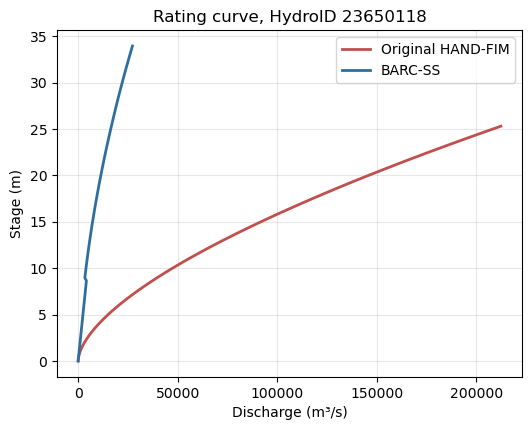

In [6]:
barc_ss.plot_rating_curve(flood_dir, huc, label=method)    # add hydroid=... for a specific reach
plt.show()

### STEP 7. NWM discharge and HAND-FIM

In [7]:
fm.getNWMretrospectivedata(huc, start_date, end_date, value_times=value_times)
fm.runOWPHANDFIM(huc)

INFO:teehr.fetching.nwm.retrospective_points:Fetching NWM retrospective point data, version: nwm30.


INFO:teehr.fetching.nwm.retrospective_points:Fetching NWM retrospective point data, version: nwm30.


NWM discharge data saved to /Users/reihanehzarrabi/Bathymetric-Adjustment-of-Rating-Curves-and-Stage-Shift-BARC-SS/examples/output/flood_11110203/discharge/nwm30_retrospective.


NWM discharge data saved to /Users/reihanehzarrabi/Bathymetric-Adjustment-of-Rating-Curves-and-Stage-Shift-BARC-SS/examples/output/flood_11110203/discharge/nwm30_retrospective.


Discharge values saved to /Users/reihanehzarrabi/Bathymetric-Adjustment-of-Rating-Curves-and-Stage-Shift-BARC-SS/examples/data/inputs/NWM_20160103000000_11110203.csv


Completed in 1.11 minutes.

Inundation mapping for 11110203 completed successfully.


### STEP 8. Map the flooded area

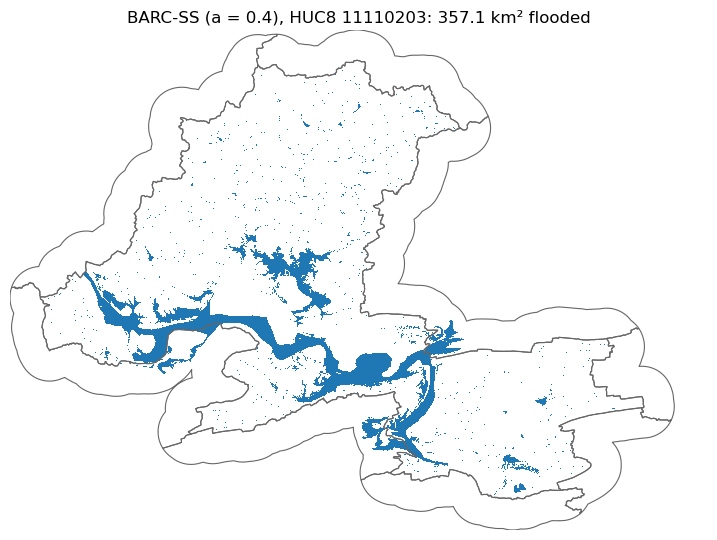

In [8]:
import glob
import geopandas as gpd
import numpy as np
import rasterio
from matplotlib.colors import ListedColormap

fim = sorted(glob.glob(f"{flood_dir}/{huc}_inundation/*_inundation.tif"))[-1]
with rasterio.open(fim) as r:
    flooded = r.read(1) > 0
    b, crs, res = r.bounds, r.crs, r.res

fig, ax = plt.subplots(figsize=(9, 7))
ax.imshow(np.ma.masked_where(~flooded, flooded), cmap=ListedColormap(["#1f78b4"]),
          extent=(b.left, b.right, b.bottom, b.top), interpolation="nearest")
gpd.read_file(f"{flood_dir}/{huc}/wbd8_clp.gpkg").to_crs(crs).boundary.plot(ax=ax, color="0.4", lw=0.8)
ax.set_title(f"{method} ({shape} = {value}), HUC8 {huc}: {flooded.sum() * res[0] * res[1] / 1e6:,.1f} km² flooded")
ax.set_axis_off()
plt.savefig(f"FIM_{huc}_{method}_{shape}{value}.png", dpi=200, bbox_inches="tight")
plt.show()

### Run again with another method or shape

FIMserv skips HAND-FIM if a flood map for the same discharge already exists, so rename the current map first. Then change the settings in STEP 2 and run STEPS 4 to 8 again (no new download needed).

In [9]:
import os
os.rename(fim, fim.replace("_inundation.tif", f"_{method}_{shape}{value}_inundation.tif"))

To map the original HAND-FIM for comparison, run `barc_ss.restore_hydrotables(flood_dir)` instead of STEPS 4 and 5.